# Anomaly Detection - Isolation Forest & LOF on Thyroid Data
**Dataset:** `thyroid_dataset.csv` (6,916 patients, 21 features, ~3.6 % labelled outliers)
**Covers:** unsupervised outlier detection with `IsolationForest` and `LocalOutlierFactor`, the `contamination` parameter, PCA for 2-D visualisation, and evaluation against the held-back labels (precision / recall / ROC-AUC).

In [1]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
import numpy as np
from sklearn.decomposition import PCA

In [2]:
df= pd.read_csv("../../data/thyroid_dataset.csv")

In [3]:
df.shape

(6916, 22)

In [4]:
df

,Age,Sex,on_thyroxine,query_on_thyroxine,on_antithyroid_medication,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,...,goitre,tumor,hypopituitary,psych,TSH,T3_measured,TT4_measured,T4U_measured,FTI_measured,Outlier_label
0,0.45,1,0,0,0,0,0,0,0,0,...,0,0,0,0,61.00000,6.0000,23.0,87.0,26.0,o
1,0.61,0,0,0,0,1,0,0,0,0,...,0,0,0,0,29.00000,15.0000,61.0,96.0,64.0,o
2,0.16,0,1,0,0,0,0,0,0,0,...,0,1,0,0,29.00000,19.0000,58.0,103.0,56.0,o
3,0.85,0,0,0,0,0,0,0,0,0,...,0,0,0,0,114.00000,3.0000,24.0,61.0,39.0,o
4,0.75,1,0,0,0,0,0,0,0,0,...,0,0,0,0,49.00000,3.0000,5.0,116.0,4.0,o
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6911,0.65,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0.00047,8.0000,154.0,75.0,204.0,n
6912,0.77,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0.00006,0.0206,125.0,107.0,117.0,n
6913,0.41,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0.00130,25.0000,125.0,114.0,109.0,n
6914,0.64,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0.00078,0.0206,106.0,88.0,121.0,n


In [5]:
X =df.drop("Outlier_label", axis= 1)
y = df["Outlier_label"]

In [6]:
sc = StandardScaler()
X_scaled =sc.fit_transform(X)

In [7]:
X_scaled

array([[-2.34449113e-02,  1.50050924e+00, -3.94405319e-01, ...,
        -1.40951598e+00, -3.74590514e-02, -1.25859776e+00],
       [ 2.40791602e-03, -6.66440415e-01, -3.94405319e-01, ...,
        -6.57814578e-01,  2.27969782e-01, -5.68029663e-01],
       [-7.03031607e-02, -6.66440415e-01,  2.53546276e+00, ...,
        -7.17159426e-01,  4.34414431e-01, -7.13412420e-01],
       ...,
       [-2.99081181e-02, -6.66440415e-01, -3.94405319e-01, ...,
         6.08208844e-01,  7.58827450e-01,  2.49748343e-01],
       [ 7.25532113e-03,  1.50050924e+00, -3.94405319e-01, ...,
         2.32358141e-01, -7.96695877e-03,  4.67822478e-01],
       [-2.18291096e-02, -6.66440415e-01, -3.94405319e-01, ...,
        -2.48028670e-02,  8.05093192e-02,  1.22538431e-01]],
      shape=(6916, 21))

In [8]:
# contamination = expected share of outliers; if unknown, leave the default "auto".
# Here it is known: ~3.6% (250 of 6,916 rows)

iff = IsolationForest(n_estimators = 200,contamination=0.036, random_state =42)
labels= iff.fit_predict(X_scaled)

In [9]:
outliers= np.sum(labels==-1)

In [10]:
print(outliers)

249


In [11]:
normal= np.sum(labels==1)

In [12]:
print(normal)

6667


In [13]:
#to visualize conv into 2d

pca= PCA(n_components=2 , random_state=42)
X_2d= pca.fit_transform(X_scaled)



<Axes: >

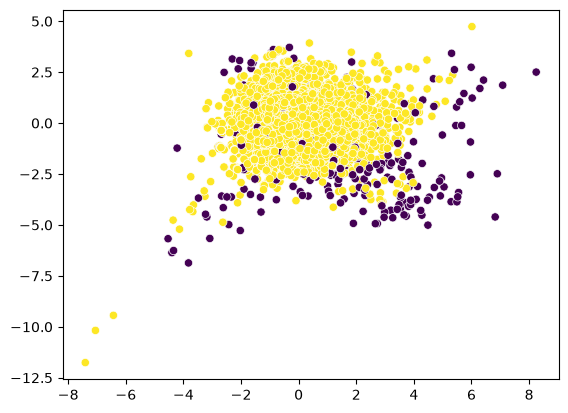

In [14]:
import seaborn as sns


sns.scatterplot(x= X_2d[:,0], y= X_2d[:,1],c=labels)

## Local Outlier Factor
LOF compares each point's local density with that of its neighbours. With `n_neighbors=2` the neighbourhood is tiny (note the duplicate-values warning) - a larger value is tried in the evaluation below.

In [15]:
#lof
lof =LocalOutlierFactor(n_neighbors=2)
labels2= lof.fit_predict(X_scaled)

<site-packages>\sklearn\neighbors\_lof.py:327: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(


In [16]:
outliers2= np.sum(labels2==-1)
print(outliers2)

1177


In [17]:
#lof
lof =LocalOutlierFactor(n_neighbors=2,contamination=0.036)
labels2= lof.fit_predict(X_scaled)

outliers2= np.sum(labels2==-1)
print(outliers2)

<site-packages>\sklearn\neighbors\_lof.py:327: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(


249


## Evaluation against the known labels
The models never saw `Outlier_label` during training - it is used here only to measure how many real outliers were caught.

In [18]:
from sklearn.metrics import classification_report, roc_auc_score

y_true = (y == "o").astype(int)  # 1 = outlier

print("Isolation Forest")
print(classification_report(y_true, (labels == -1).astype(int), target_names=["normal", "outlier"]))
print("ROC-AUC:", roc_auc_score(y_true, -iff.score_samples(X_scaled)))

Isolation Forest
              precision    recall  f1-score   support

      normal       0.97      0.97      0.97      6666
     outlier       0.08      0.08      0.08       250

    accuracy                           0.93      6916
   macro avg       0.52      0.52      0.52      6916
weighted avg       0.93      0.93      0.93      6916

ROC-AUC: 0.5974659465946595


In [19]:
lof20 = LocalOutlierFactor(n_neighbors=20, contamination=0.036)
lof_labels = lof20.fit_predict(X_scaled)

print("Local Outlier Factor (n_neighbors=20)")
print(classification_report(y_true, (lof_labels == -1).astype(int), target_names=["normal", "outlier"]))
print("ROC-AUC:", roc_auc_score(y_true, -lof20.negative_outlier_factor_))

Local Outlier Factor (n_neighbors=20)
              precision    recall  f1-score   support

      normal       0.97      0.97      0.97      6666
     outlier       0.16      0.16      0.16       250

    accuracy                           0.94      6916
   macro avg       0.57      0.57      0.57      6916
weighted avg       0.94      0.94      0.94      6916

ROC-AUC: 0.6833747374737474
